In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
from pathlib import Path

current_path = Path.cwd()

if (current_path / "src").exists():
    PROJECT_ROOT = current_path
elif (current_path.parent / "src").exists():
    PROJECT_ROOT = current_path.parent
else:
    raise FileNotFoundError("No se encontró la carpeta src.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /Users/macbook/Usach/TesisxD/cosmo_singularities


In [13]:
import numpy as np
import matplotlib.pyplot as plt

from src.models import (
    PhantomQ0Params,
    PhantomQ0Model,
    PhantomQAlphaRhoParams,
    PhantomQAlphaRhoModel,
)

In [14]:
import pandas as pd
from pathlib import Path

# Buscar automáticamente el archivo en las dos ubicaciones posibles
possible_paths = [
    PROJECT_ROOT / "data" / "processed" / "phantom_models_dataset.csv",
    PROJECT_ROOT / "notebooks" / "data" / "processed" / "phantom_models_dataset.csv",
]

csv_path = None

for path in possible_paths:
    if path.exists():
        csv_path = path
        break

if csv_path is None:
    raise FileNotFoundError("No se encontró phantom_models_dataset.csv.")

print("Archivo encontrado en:", csv_path)

df_all = pd.read_csv(csv_path)

df_all.head()

Archivo encontrado en: /Users/macbook/Usach/TesisxD/cosmo_singularities/data/processed/phantom_models_dataset.csv


,model_name,A,nu,alpha,rho0,a0,t0,singularity_type,singular_time,valid_solution,...,a_max,H_initial,H_final,H_max,P_initial,P_final,P_abs_max,Hdot_initial,Hdot_final,Hdot_max
0,phantom_q0,0.5,-1.0,NaN,0.5,1.0,0.0,Type II / Sudden singularity,NaN,True,...,35129.050795,0.408248,1.369412,1.369412,-1.500000,-5.714740,5.714740,0.500000,0.044438,0.500000
1,phantom_q0,0.5,-1.0,NaN,1.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,54376.907471,0.577350,1.391178,1.391178,-1.500000,-5.892241,5.892241,0.250000,0.043058,0.250000
2,phantom_q0,0.5,-1.0,NaN,2.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,147751.395138,0.816497,1.449319,1.449319,-2.250000,-6.380921,6.380921,0.125000,0.039673,0.125000
3,phantom_q0,0.5,-0.5,NaN,0.5,1.0,0.0,Type II / Sudden singularity,NaN,True,...,191912.682973,0.408248,1.747403,1.747403,-1.207107,-9.325456,9.325456,0.353553,0.082601,0.353553
4,phantom_q0,0.5,-0.5,NaN,1.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,400309.791321,0.577350,1.794459,1.794459,-1.500000,-9.821124,9.821124,0.250000,0.080435,0.250000


In [15]:
def make_time_grid_from_dataset_row(
    row,
    t0=0.0,
    t_end_default=10.0,
    n_points=1000,
    fraction=0.95,
):
    """
    Construye una grilla temporal usando el tiempo singular guardado
    en el dataset si existe.
    """

    ts = row["singular_time"]

    if np.isfinite(ts):
        t_end = t0 + fraction * (ts - t0)
    else:
        t_end = t_end_default

    if t_end <= t0:
        raise ValueError("t_end <= t0. Revisa el tiempo singular del caso.")

    return np.linspace(t0, t_end, n_points)


def build_model_from_dataset_row(row):
    """
    Reconstruye el modelo correspondiente a una fila del dataset.
    """

    model_name = row["model_name"]

    if model_name == "phantom_q0":
        params = PhantomQ0Params(
            A=float(row["A"]),
            nu=float(row["nu"]),
            rho0=float(row["rho0"]),
            a0=float(row["a0"]),
            t0=float(row["t0"]),
        )

        return PhantomQ0Model(params)

    if model_name == "phantom_qalpha_rho":
        params = PhantomQAlphaRhoParams(
            A=float(row["A"]),
            nu=float(row["nu"]),
            alpha=float(row["alpha"]),
            rho0=float(row["rho0"]),
            a0=float(row["a0"]),
            t0=float(row["t0"]),
        )

        return PhantomQAlphaRhoModel(params)

    raise ValueError(f"Modelo no reconocido: {model_name}")

In [16]:
df_valid = df_all[df_all["valid_solution"]].copy()

In [17]:
selected_rows = (
    df_valid
    .groupby(["model_name", "singularity_type"], group_keys=False)
    .apply(lambda x: x.sample(min(len(x), 3), random_state=42))
    .reset_index(drop=True)
)

selected_rows[
    ["model_name", "A", "nu", "alpha", "rho0", "singularity_type", "singular_time"]
]

/var/folders/7v/mpqjvkxx00lf3_k_1wpn9jsw0000gn/T/ipykernel_2689/3659512874.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min(len(x), 3), random_state=42))


,model_name,A,nu,alpha,rho0,singularity_type,singular_time
0,phantom_q0,0.5,0.50,NaN,0.5,Non singular,NaN
1,phantom_q0,0.5,0.50,NaN,1.0,Non singular,NaN
2,phantom_q0,0.5,0.50,NaN,2.0,Non singular,NaN
3,phantom_q0,0.5,-1.00,NaN,0.5,Type II / Sudden singularity,NaN
4,phantom_q0,0.5,-1.00,NaN,1.0,Type II / Sudden singularity,NaN
5,phantom_q0,1.0,-1.00,NaN,2.0,Type II / Sudden singularity,NaN
6,phantom_q0,2.0,0.25,NaN,1.0,Type IV,NaN
7,phantom_q0,0.5,0.25,NaN,1.0,Type IV,NaN
8,phantom_q0,1.0,0.25,NaN,2.0,Type IV,NaN
9,phantom_qalpha_rho,0.5,0.50,-0.5,0.5,Non singular,NaN


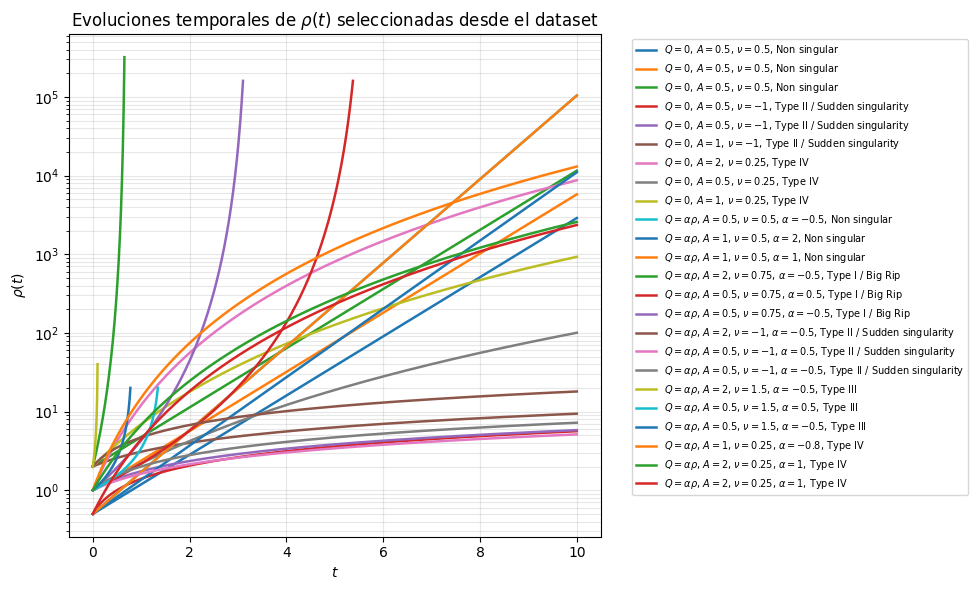

In [18]:
plt.figure(figsize=(10, 6))

for _, row in selected_rows.iterrows():
    try:
        model = build_model_from_dataset_row(row)

        t_values = make_time_grid_from_dataset_row(
            row,
            t0=float(row["t0"]),
            t_end_default=10.0,
            n_points=1000,
            fraction=0.95,
        )

        df_bg = model.evaluate_background_t(t_values)

        if row["model_name"] == "phantom_q0":
            label = (
                rf"$Q=0$, "
                rf"$A={row['A']:.2g}$, "
                rf"$\nu={row['nu']:.2g}$, "
                rf"{row['singularity_type']}"
            )
        else:
            label = (
                rf"$Q=\alpha\rho$, "
                rf"$A={row['A']:.2g}$, "
                rf"$\nu={row['nu']:.2g}$, "
                rf"$\alpha={row['alpha']:.2g}$, "
                rf"{row['singularity_type']}"
            )

        plt.plot(
            df_bg["t"],
            df_bg["rho"],
            linewidth=1.8,
            label=label,
        )

    except Exception as e:
        print(f"No se pudo graficar una fila: {e}")

plt.yscale("log")
plt.xlabel(r"$t$")
plt.ylabel(r"$\rho(t)$")
plt.title(r"Evoluciones temporales de $\rho(t)$ seleccionadas desde el dataset")
plt.legend(fontsize=7, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
df_alpha = df_valid[df_valid["model_name"] == "phantom_qalpha_rho"].copy()

selected_alpha_rows = (
    df_alpha
    .groupby("singularity_type", group_keys=False)
    .apply(lambda x: x.sample(min(len(x), 4), random_state=10))
    .reset_index(drop=True)
)

selected_alpha_rows[
    ["A", "nu", "alpha", "rho0", "singularity_type", "singular_time"]
]

/var/folders/7v/mpqjvkxx00lf3_k_1wpn9jsw0000gn/T/ipykernel_2689/1203831623.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min(len(x), 4), random_state=10))


,A,nu,alpha,rho0,singularity_type,singular_time
0,0.5,0.50,0.5,1.0,Non singular,NaN
1,0.5,0.50,1.0,1.0,Non singular,NaN
2,0.5,0.50,0.0,2.0,Non singular,NaN
3,0.5,0.50,0.5,0.5,Non singular,NaN
4,2.0,0.75,-0.8,2.0,Type I / Big Rip,0.434237
5,2.0,1.00,-0.8,0.5,Type I / Big Rip,0.365148
6,1.0,1.00,2.0,2.0,Type I / Big Rip,1.414214
7,2.0,0.75,1.0,1.0,Type I / Big Rip,1.632993
8,2.0,-1.00,-0.8,2.0,Type II / Sudden singularity,NaN
9,2.0,-0.50,-0.8,0.5,Type II / Sudden singularity,NaN


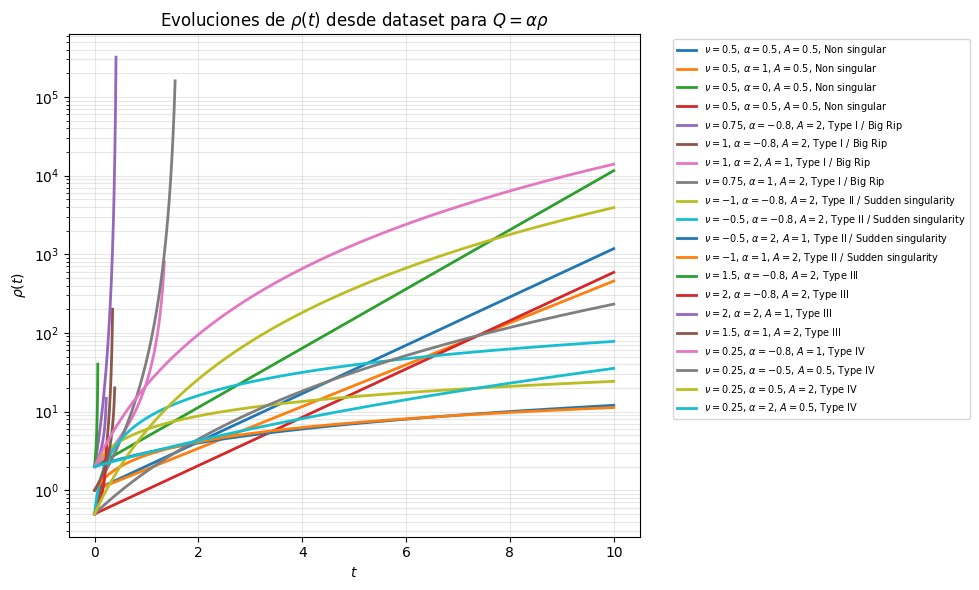

In [20]:
plt.figure(figsize=(10, 6))

for _, row in selected_alpha_rows.iterrows():
    try:
        model = build_model_from_dataset_row(row)

        t_values = make_time_grid_from_dataset_row(
            row,
            t0=float(row["t0"]),
            t_end_default=10.0,
            n_points=1000,
            fraction=0.95,
        )

        df_bg = model.evaluate_background_t(t_values)

        label = (
            rf"$\nu={row['nu']:.2g}$, "
            rf"$\alpha={row['alpha']:.2g}$, "
            rf"$A={row['A']:.2g}$, "
            rf"{row['singularity_type']}"
        )

        plt.plot(df_bg["t"], df_bg["rho"], linewidth=2, label=label)

    except Exception as e:
        print(f"No se pudo graficar una fila: {e}")

plt.yscale("log")
plt.xlabel(r"$t$")
plt.ylabel(r"$\rho(t)$")
plt.title(r"Evoluciones de $\rho(t)$ desde dataset para $Q=\alpha\rho$")
plt.legend(fontsize=7, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

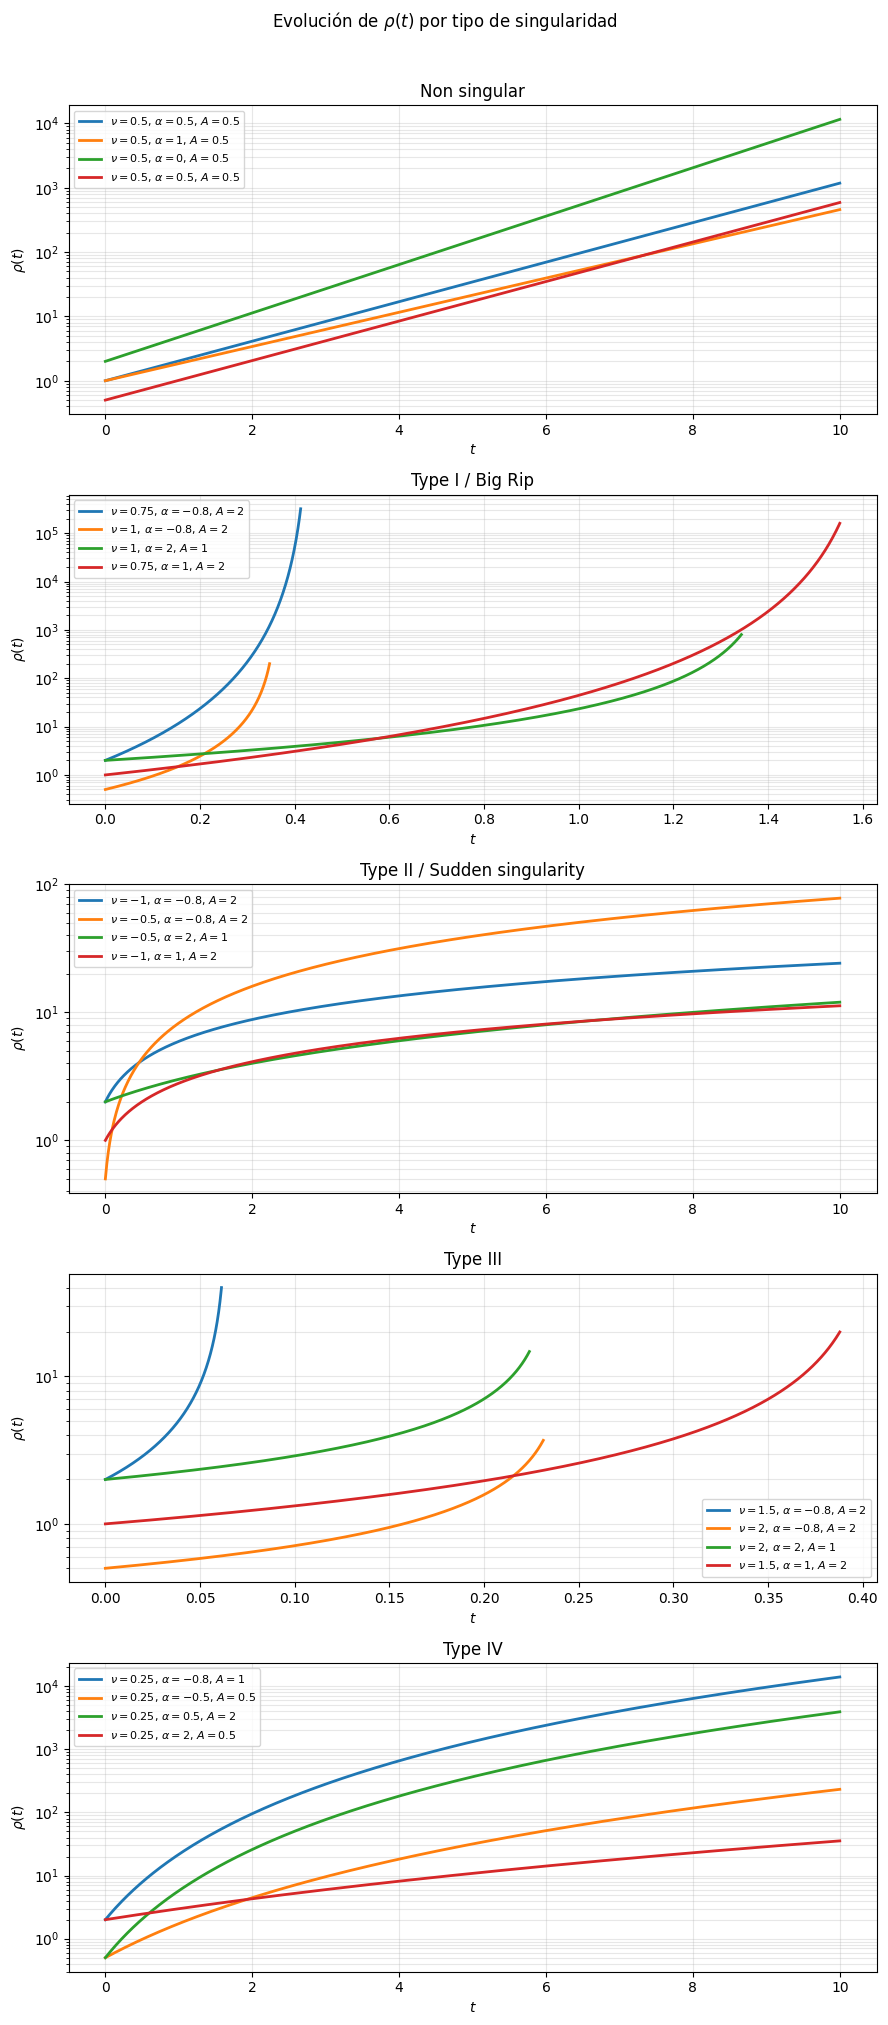

In [21]:
singularity_types = selected_alpha_rows["singularity_type"].unique()

fig, axes = plt.subplots(
    len(singularity_types),
    1,
    figsize=(9, 4 * len(singularity_types)),
    sharex=False,
)

if len(singularity_types) == 1:
    axes = [axes]

for ax, singularity_type in zip(axes, singularity_types):
    subset = selected_alpha_rows[
        selected_alpha_rows["singularity_type"] == singularity_type
    ]

    for _, row in subset.iterrows():
        try:
            model = build_model_from_dataset_row(row)

            t_values = make_time_grid_from_dataset_row(
                row,
                t0=float(row["t0"]),
                t_end_default=10.0,
                n_points=1000,
                fraction=0.95,
            )

            df_bg = model.evaluate_background_t(t_values)

            label = (
                rf"$\nu={row['nu']:.2g}$, "
                rf"$\alpha={row['alpha']:.2g}$, "
                rf"$A={row['A']:.2g}$"
            )

            ax.plot(df_bg["t"], df_bg["rho"], linewidth=2, label=label)

        except Exception as e:
            print(f"No se pudo graficar una fila: {e}")

    ax.set_yscale("log")
    ax.set_xlabel(r"$t$")
    ax.set_ylabel(r"$\rho(t)$")
    ax.set_title(singularity_type)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle(r"Evolución de $\rho(t)$ por tipo de singularidad", y=1.01)
plt.tight_layout()
plt.show()

In [22]:
row = selected_alpha_rows.iloc[0]

model = build_model_from_dataset_row(row)

t_values = make_time_grid_from_dataset_row(
    row,
    t0=float(row["t0"]),
    t_end_default=10.0,
    n_points=1000,
    fraction=0.95,
)

df_bg = model.evaluate_background_t(t_values)

row[["model_name", "A", "nu", "alpha", "rho0", "singularity_type", "singular_time"]]

model_name          phantom_qalpha_rho
A                                  0.5
nu                                 0.5
alpha                              0.5
rho0                               1.0
singularity_type          Non singular
singular_time                      NaN
Name: 0, dtype: object

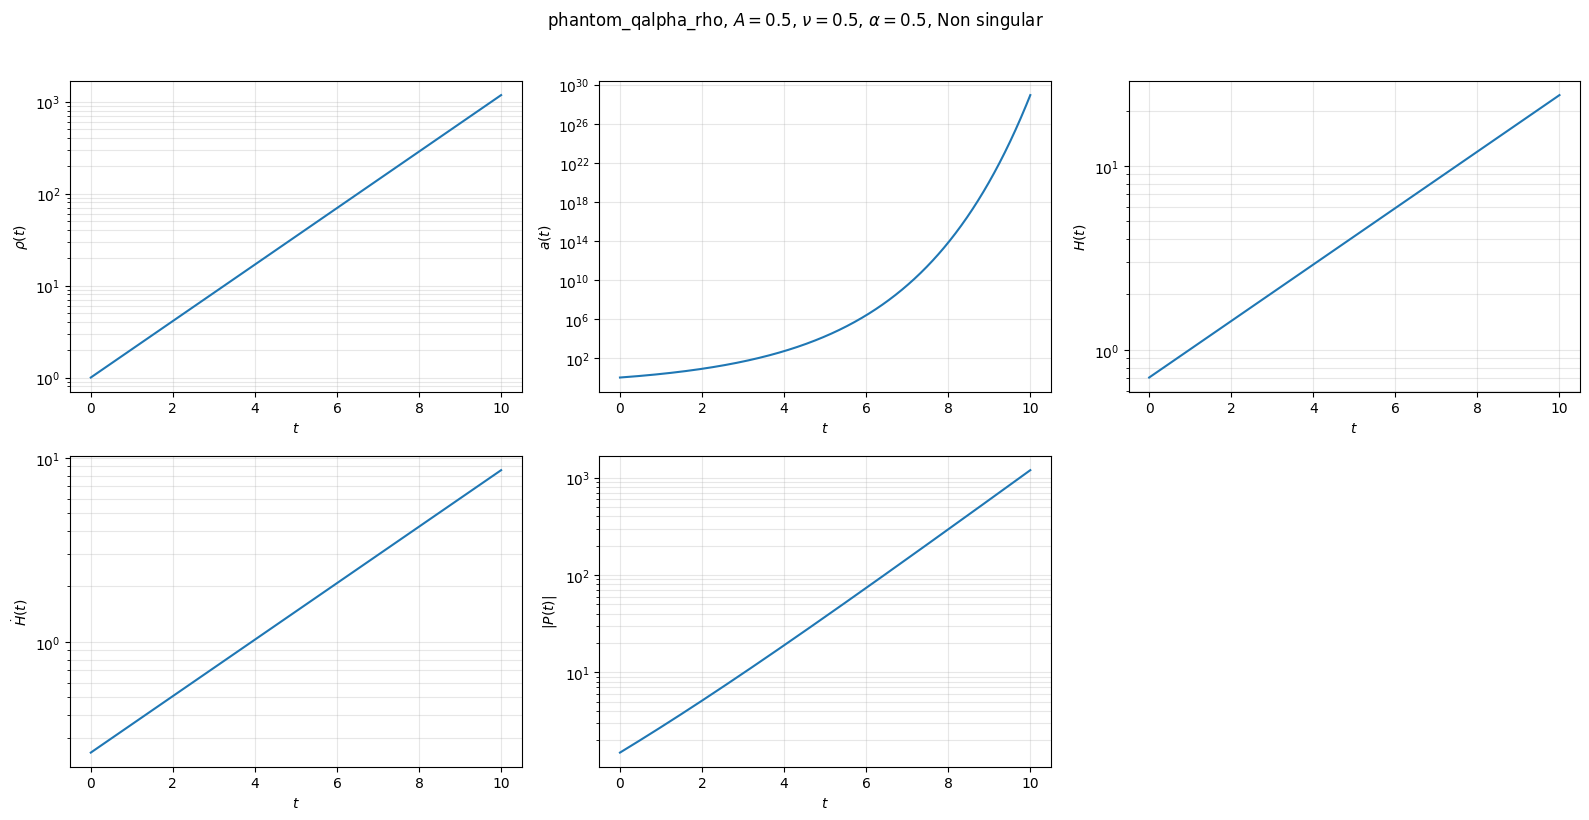

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

quantities = [
    ("rho", r"$\rho(t)$"),
    ("a", r"$a(t)$"),
    ("H", r"$H(t)$"),
    ("Hdot", r"$\dot H(t)$"),
]

for ax, (column, ylabel) in zip(axes, quantities):
    ax.plot(df_bg["t"], df_bg[column])
    ax.set_yscale("log")
    ax.set_xlabel(r"$t$")
    ax.set_ylabel(ylabel)
    ax.grid(True, which="both", alpha=0.3)

axes[4].plot(df_bg["t"], np.abs(df_bg["P"]))
axes[4].set_yscale("log")
axes[4].set_xlabel(r"$t$")
axes[4].set_ylabel(r"$|P(t)|$")
axes[4].grid(True, which="both", alpha=0.3)

axes[5].axis("off")

fig.suptitle(
    rf"{row['model_name']}, "
    rf"$A={row['A']:.2g}$, "
    rf"$\nu={row['nu']:.2g}$, "
    rf"$\alpha={row['alpha']:.2g}$, "
    rf"{row['singularity_type']}",
    y=1.02,
)

plt.tight_layout()
plt.show()

## XD

In [2]:
possible_paths = [
    PROJECT_ROOT / "data" / "processed" / "phantom_models_dataset.csv",
    PROJECT_ROOT / "notebooks" / "data" / "processed" / "phantom_models_dataset.csv",
]

csv_path = None

for path in possible_paths:
    if path.exists():
        csv_path = path
        break

if csv_path is None:
    raise FileNotFoundError("No se encontró phantom_models_dataset.csv.")

print("Archivo encontrado en:", csv_path)

df_all = pd.read_csv(csv_path)

df_all.head()

Archivo encontrado en: /Users/macbook/Usach/TesisxD/cosmo_singularities/data/processed/phantom_models_dataset.csv


,model_name,A,nu,alpha,rho0,a0,t0,singularity_type,singular_time,valid_solution,...,a_max,H_initial,H_final,H_max,P_initial,P_final,P_abs_max,Hdot_initial,Hdot_final,Hdot_max
0,phantom_q0,0.5,-1.0,NaN,0.5,1.0,0.0,Type II / Sudden singularity,NaN,True,...,35129.050795,0.408248,1.369412,1.369412,-1.500000,-5.714740,5.714740,0.500000,0.044438,0.500000
1,phantom_q0,0.5,-1.0,NaN,1.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,54376.907471,0.577350,1.391178,1.391178,-1.500000,-5.892241,5.892241,0.250000,0.043058,0.250000
2,phantom_q0,0.5,-1.0,NaN,2.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,147751.395138,0.816497,1.449319,1.449319,-2.250000,-6.380921,6.380921,0.125000,0.039673,0.125000
3,phantom_q0,0.5,-0.5,NaN,0.5,1.0,0.0,Type II / Sudden singularity,NaN,True,...,191912.682973,0.408248,1.747403,1.747403,-1.207107,-9.325456,9.325456,0.353553,0.082601,0.353553
4,phantom_q0,0.5,-0.5,NaN,1.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,400309.791321,0.577350,1.794459,1.794459,-1.500000,-9.821124,9.821124,0.250000,0.080435,0.250000


In [3]:
from src.models import (
    PhantomQ0Params,
    PhantomQ0Model,
    PhantomQAlphaRhoParams,
    PhantomQAlphaRhoModel,
)

In [4]:
df_all = df_all.copy()

# Asegurar que valid_solution sea booleano
if df_all["valid_solution"].dtype == object:
    df_all["valid_solution"] = df_all["valid_solution"].map(
        {"True": True, "False": False, True: True, False: False}
    )

df_valid = df_all[df_all["valid_solution"] == True].copy()

df_valid[
    ["model_name", "A", "nu", "alpha", "rho0", "singularity_type", "singular_time"]
].head()

,model_name,A,nu,alpha,rho0,singularity_type,singular_time
0,phantom_q0,0.5,-1.0,NaN,0.5,Type II / Sudden singularity,NaN
1,phantom_q0,0.5,-1.0,NaN,1.0,Type II / Sudden singularity,NaN
2,phantom_q0,0.5,-1.0,NaN,2.0,Type II / Sudden singularity,NaN
3,phantom_q0,0.5,-0.5,NaN,0.5,Type II / Sudden singularity,NaN
4,phantom_q0,0.5,-0.5,NaN,1.0,Type II / Sudden singularity,NaN


In [5]:
def build_model_from_dataset_row(row):
    """
    Reconstruye el modelo cosmológico a partir de una fila del dataset.
    """

    model_name = row["model_name"]

    if model_name == "phantom_q0":
        params = PhantomQ0Params(
            A=float(row["A"]),
            nu=float(row["nu"]),
            rho0=float(row["rho0"]),
            a0=float(row["a0"]),
            t0=float(row["t0"]),
        )

        return PhantomQ0Model(params)

    if model_name == "phantom_qalpha_rho":
        params = PhantomQAlphaRhoParams(
            A=float(row["A"]),
            nu=float(row["nu"]),
            alpha=float(row["alpha"]),
            rho0=float(row["rho0"]),
            a0=float(row["a0"]),
            t0=float(row["t0"]),
        )

        return PhantomQAlphaRhoModel(params)

    raise ValueError(f"Modelo no reconocido: {model_name}")


def make_time_grid_from_dataset_row(
    row,
    n_points=1200,
    fraction=0.95,
    t_end_default=10.0,
):
    """
    Construye una grilla temporal usando el tiempo singular del dataset
    si existe. Si no existe, usa t_end_default.
    """

    t0 = float(row["t0"])
    ts = row["singular_time"]

    if np.isfinite(ts):
        t_end = t0 + fraction * (float(ts) - t0)
    else:
        t_end = t_end_default

    if t_end <= t0:
        raise ValueError("t_end <= t0. Revisa el caso seleccionado.")

    return np.linspace(t0, t_end, n_points)


def filter_close(df, column, value, tol=1e-12):
    """
    Filtra un DataFrame usando comparación numérica aproximada.
    """

    return df[np.isclose(df[column].astype(float), float(value), atol=tol, rtol=0.0)]


def select_cases_by_values(df, column, values, sort_by=None):
    """
    Selecciona una fila por cada valor pedido.
    """

    rows = []

    for value in values:
        subset = filter_close(df, column, value)

        if len(subset) == 0:
            print(f"No se encontró {column} = {value}")
            continue

        rows.append(subset.iloc[[0]])

    if len(rows) == 0:
        return pd.DataFrame()

    result = pd.concat(rows, ignore_index=True)

    if sort_by is not None:
        result = result.sort_values(sort_by).reset_index(drop=True)

    return result

In [6]:
def plot_quantity_for_rows(
    rows,
    quantity,
    ylabel,
    title,
    log_y=True,
    n_points=1200,
    fraction=0.95,
    t_end_default=10.0,
):
    """
    Grafica una cantidad temporal para varias filas del dataset.
    """

    plt.figure(figsize=(9, 5.5))

    for _, row in rows.iterrows():
        try:
            model = build_model_from_dataset_row(row)

            t_values = make_time_grid_from_dataset_row(
                row,
                n_points=n_points,
                fraction=fraction,
                t_end_default=t_end_default,
            )

            df_bg = model.evaluate_background_t(t_values)

            if quantity == "P_abs":
                y_values = np.abs(df_bg["P"])
            else:
                y_values = df_bg[quantity]

            if row["model_name"] == "phantom_q0":
                label = (
                    rf"$Q=0$, "
                    rf"$A={row['A']:.2g}$, "
                    rf"$\nu={row['nu']:.2g}$"
                )
            else:
                label = (
                    rf"$\alpha={row['alpha']:.2g}$, "
                    rf"$A={row['A']:.2g}$, "
                    rf"$\nu={row['nu']:.2g}$"
                )

            plt.plot(
                df_bg["t"],
                y_values,
                linewidth=2,
                label=label,
            )

        except Exception as e:
            print(f"No se pudo graficar una fila: {e}")

    if log_y:
        plt.yscale("log")

    plt.xlabel(r"$t$")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend(fontsize=8)
    plt.grid(True, which="both", alpha=0.3)
    plt.tight_layout()
    plt.show()

## Parte A

In [7]:
df_alpha = df_valid[df_valid["model_name"] == "phantom_qalpha_rho"].copy()

df_alpha_base = df_alpha.copy()
df_alpha_base = filter_close(df_alpha_base, "A", 1.0)
df_alpha_base = filter_close(df_alpha_base, "nu", 0.75)
df_alpha_base = filter_close(df_alpha_base, "rho0", 1.0)

alpha_values = [-0.5, 0.0, 0.5, 1.0, 2.0]

rows_alpha_effect = select_cases_by_values(
    df_alpha_base,
    column="alpha",
    values=alpha_values,
    sort_by="alpha",
)

rows_alpha_effect[
    ["model_name", "A", "nu", "alpha", "rho0", "singularity_type", "singular_time"]
]

,model_name,A,nu,alpha,rho0,singularity_type,singular_time
0,phantom_qalpha_rho,1.0,0.75,-0.5,1.0,Type I / Big Rip,1.632993
1,phantom_qalpha_rho,1.0,0.75,0.0,1.0,Type I / Big Rip,2.309401
2,phantom_qalpha_rho,1.0,0.75,0.5,1.0,Type I / Big Rip,2.828427
3,phantom_qalpha_rho,1.0,0.75,1.0,1.0,Type I / Big Rip,3.265986
4,phantom_qalpha_rho,1.0,0.75,2.0,1.0,Type I / Big Rip,4.000000


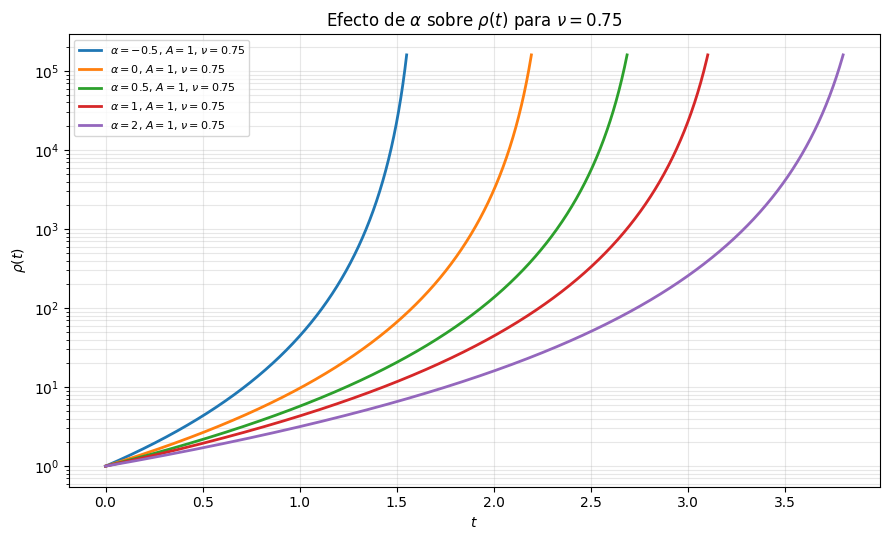

In [8]:
plot_quantity_for_rows(
    rows_alpha_effect,
    quantity="rho",
    ylabel=r"$\rho(t)$",
    title=r"Efecto de $\alpha$ sobre $\rho(t)$ para $\nu=0.75$",
)

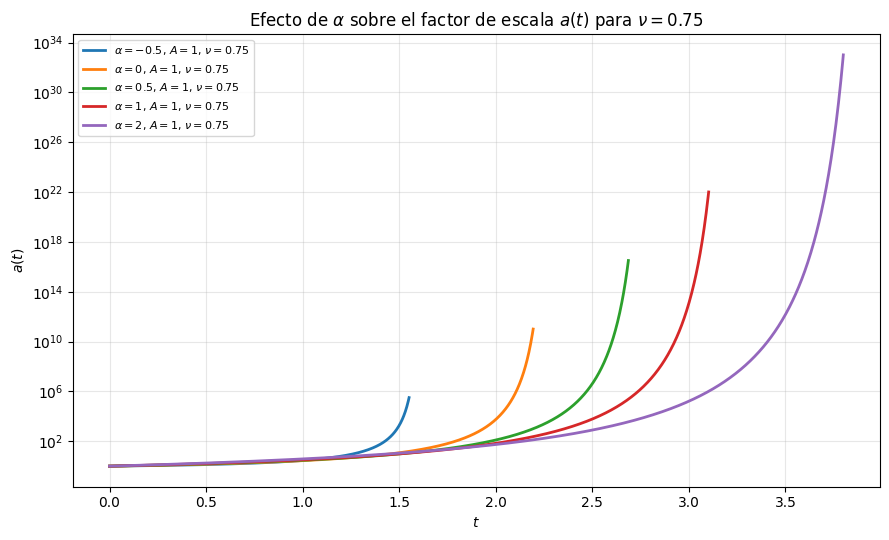

In [9]:
plot_quantity_for_rows(
    rows_alpha_effect,
    quantity="a",
    ylabel=r"$a(t)$",
    title=r"Efecto de $\alpha$ sobre el factor de escala $a(t)$ para $\nu=0.75$",
)

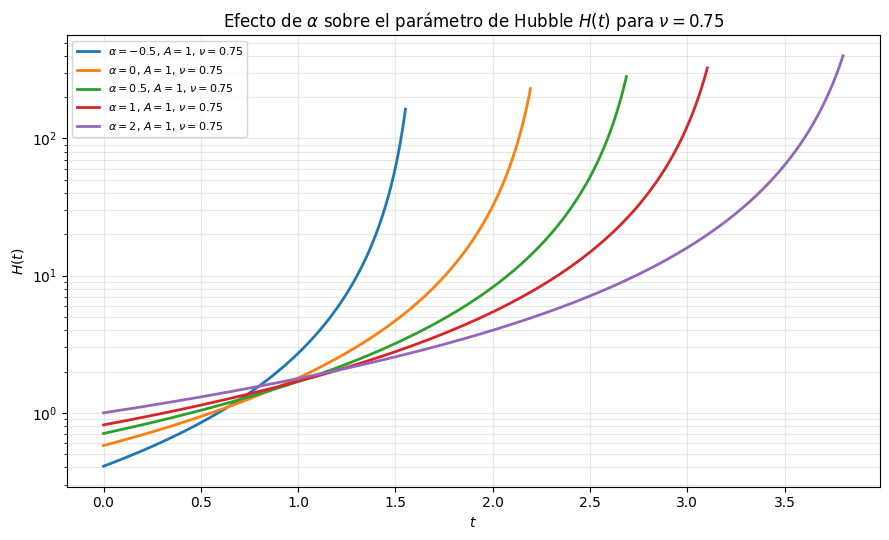

In [10]:
plot_quantity_for_rows(
    rows_alpha_effect,
    quantity="H",
    ylabel=r"$H(t)$",
    title=r"Efecto de $\alpha$ sobre el parámetro de Hubble $H(t)$ para $\nu=0.75$",
)

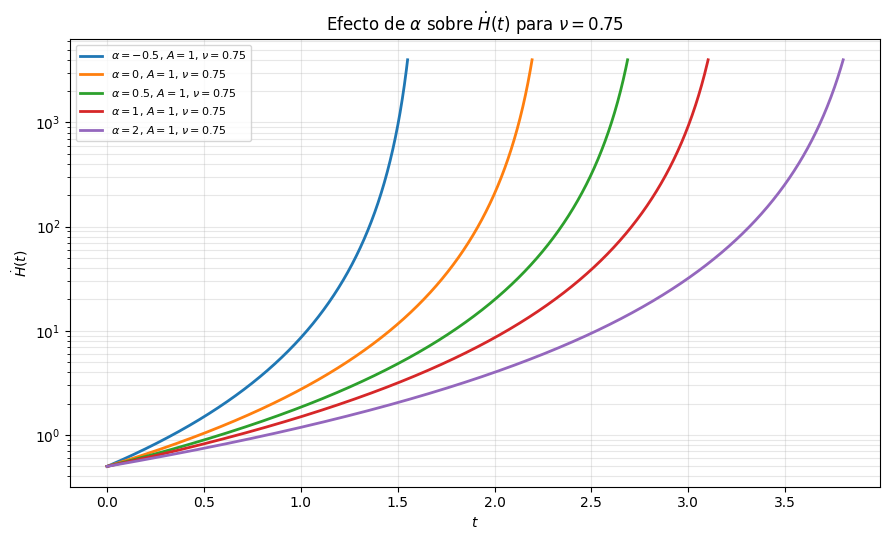

In [11]:
plot_quantity_for_rows(
    rows_alpha_effect,
    quantity="Hdot",
    ylabel=r"$\dot H(t)$",
    title=r"Efecto de $\alpha$ sobre $\dot H(t)$ para $\nu=0.75$",
)

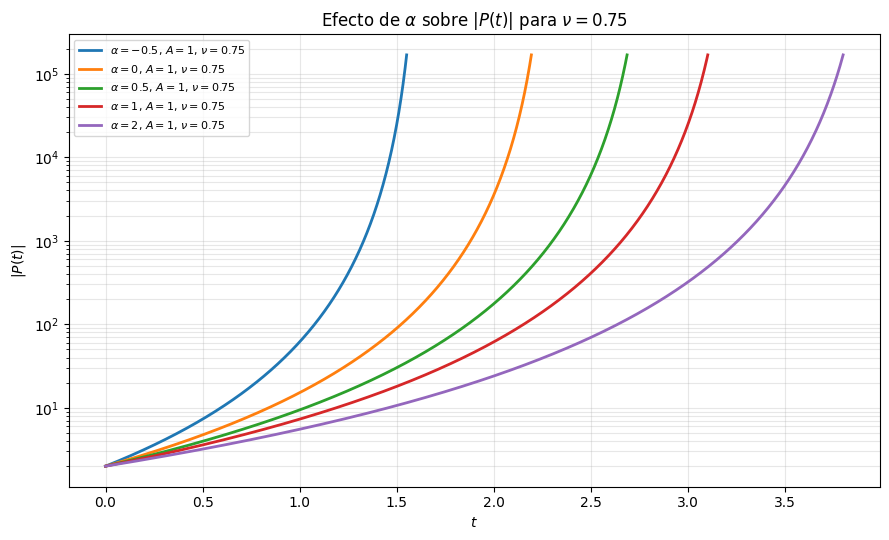

In [12]:
plot_quantity_for_rows(
    rows_alpha_effect,
    quantity="P_abs",
    ylabel=r"$|P(t)|$",
    title=r"Efecto de $\alpha$ sobre $|P(t)|$ para $\nu=0.75$",
)

## Parte B

In [13]:
df_nu_base = df_alpha.copy()
df_nu_base = filter_close(df_nu_base, "A", 1.0)
df_nu_base = filter_close(df_nu_base, "alpha", 0.5)
df_nu_base = filter_close(df_nu_base, "rho0", 1.0)

nu_values = [-1.0, 0.25, 0.75, 1.5]

rows_nu_effect = select_cases_by_values(
    df_nu_base,
    column="nu",
    values=nu_values,
    sort_by="nu",
)

rows_nu_effect[
    ["model_name", "A", "nu", "alpha", "rho0", "singularity_type", "singular_time"]
]

,model_name,A,nu,alpha,rho0,singularity_type,singular_time
0,phantom_qalpha_rho,1.0,-1.00,0.5,1.0,Type II / Sudden singularity,NaN
1,phantom_qalpha_rho,1.0,0.25,0.5,1.0,Type IV,NaN
2,phantom_qalpha_rho,1.0,0.75,0.5,1.0,Type I / Big Rip,2.828427
3,phantom_qalpha_rho,1.0,1.50,0.5,1.0,Type III,0.707107


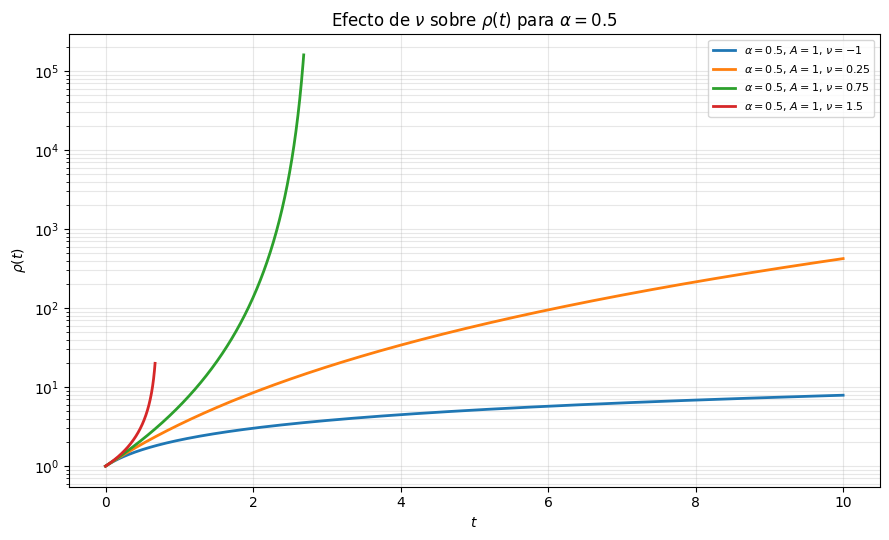

In [14]:
plot_quantity_for_rows(
    rows_nu_effect,
    quantity="rho",
    ylabel=r"$\rho(t)$",
    title=r"Efecto de $\nu$ sobre $\rho(t)$ para $\alpha=0.5$",
)

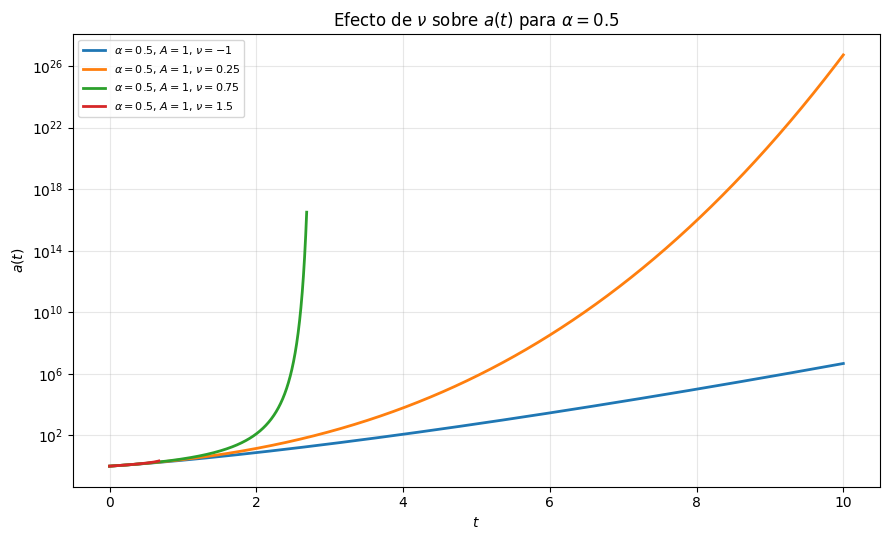

In [15]:
plot_quantity_for_rows(
    rows_nu_effect,
    quantity="a",
    ylabel=r"$a(t)$",
    title=r"Efecto de $\nu$ sobre $a(t)$ para $\alpha=0.5$",
)

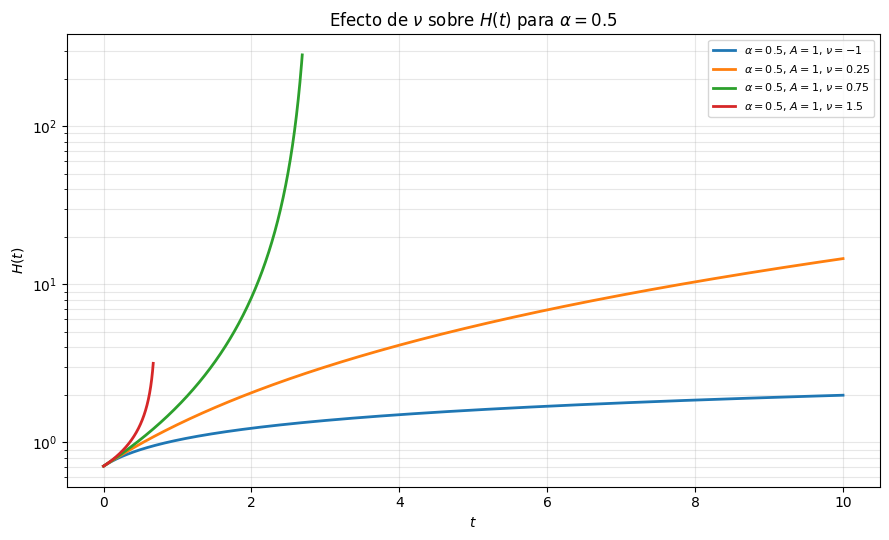

In [16]:
plot_quantity_for_rows(
    rows_nu_effect,
    quantity="H",
    ylabel=r"$H(t)$",
    title=r"Efecto de $\nu$ sobre $H(t)$ para $\alpha=0.5$",
)

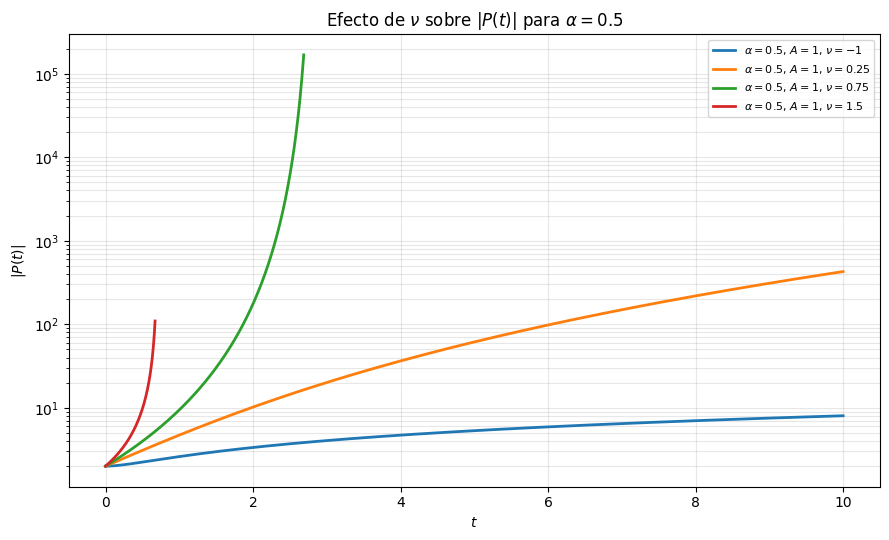

In [17]:
plot_quantity_for_rows(
    rows_nu_effect,
    quantity="P_abs",
    ylabel=r"$|P(t)|$",
    title=r"Efecto de $\nu$ sobre $|P(t)|$ para $\alpha=0.5$",
)

## Parte C

In [20]:
df_q0 = df_valid[df_valid["model_name"] == "phantom_q0"].copy()

row_q0_candidates = df_q0.copy()
row_q0_candidates = filter_close(row_q0_candidates, "A", 1.0)
row_q0_candidates = filter_close(row_q0_candidates, "nu", 0.75)
row_q0_candidates = filter_close(row_q0_candidates, "rho0", 1.0)

print("Número de candidatos Q=0:", len(row_q0_candidates))

row_q0_candidates[
    ["model_name", "A", "nu", "alpha", "rho0", "singularity_type", "singular_time"]
]

df_qalpha_compare = df_alpha.copy()
df_qalpha_compare = filter_close(df_qalpha_compare, "A", 1.0)
df_qalpha_compare = filter_close(df_qalpha_compare, "nu", 0.75)
df_qalpha_compare = filter_close(df_qalpha_compare, "rho0", 1.0)

rows_qalpha_compare = select_cases_by_values(
    df_qalpha_compare,
    column="alpha",
    values=[-0.5, 0.5, 1.0, 2.0],
    sort_by="alpha",
)

rows_compare = pd.concat(
    [row_q0, rows_qalpha_compare],
    ignore_index=True,
)

rows_compare[
    ["model_name", "A", "nu", "alpha", "rho0", "singularity_type", "singular_time"]
]

Número de candidatos Q=0: 0


,model_name,A,nu,alpha,rho0,singularity_type,singular_time
0,phantom_qalpha_rho,1.0,0.75,-0.5,1.0,Type I / Big Rip,1.632993
1,phantom_qalpha_rho,1.0,0.75,0.5,1.0,Type I / Big Rip,2.828427
2,phantom_qalpha_rho,1.0,0.75,1.0,1.0,Type I / Big Rip,3.265986
3,phantom_qalpha_rho,1.0,0.75,2.0,1.0,Type I / Big Rip,4.000000


In [21]:
def select_closest_case(df, A=None, nu=None, alpha=None, rho0=None):
    """
    Selecciona la fila más cercana a los parámetros pedidos.
    """

    subset = df.copy()

    distance = np.zeros(len(subset))

    if A is not None:
        distance += (subset["A"].astype(float) - float(A))**2

    if nu is not None:
        distance += (subset["nu"].astype(float) - float(nu))**2

    if alpha is not None and "alpha" in subset.columns:
        alpha_values = subset["alpha"].astype(float)
        distance += (alpha_values - float(alpha))**2

    if rho0 is not None:
        distance += (subset["rho0"].astype(float) - float(rho0))**2

    subset = subset.copy()
    subset["distance"] = distance

    return subset.sort_values("distance").iloc[[0]].drop(columns=["distance"])

In [22]:
df_q0 = df_valid[df_valid["model_name"] == "phantom_q0"].copy()
df_alpha = df_valid[df_valid["model_name"] == "phantom_qalpha_rho"].copy()

row_q0 = select_closest_case(
    df_q0,
    A=1.0,
    nu=0.75,
    rho0=1.0,
)

rows_qalpha_compare = []

for alpha_value in [-0.5, 0.5, 1.0, 2.0]:
    row_alpha = select_closest_case(
        df_alpha,
        A=1.0,
        nu=0.75,
        alpha=alpha_value,
        rho0=1.0,
    )

    rows_qalpha_compare.append(row_alpha)

rows_qalpha_compare = pd.concat(rows_qalpha_compare, ignore_index=True)

rows_compare = pd.concat(
    [row_q0, rows_qalpha_compare],
    ignore_index=True,
)

rows_compare[
    ["model_name", "A", "nu", "alpha", "rho0", "singularity_type", "singular_time"]
]

,model_name,A,nu,alpha,rho0,singularity_type,singular_time
0,phantom_q0,1.0,0.25,NaN,1.0,Type IV,NaN
1,phantom_qalpha_rho,1.0,0.75,-0.5,1.0,Type I / Big Rip,1.632993
2,phantom_qalpha_rho,1.0,0.75,0.5,1.0,Type I / Big Rip,2.828427
3,phantom_qalpha_rho,1.0,0.75,1.0,1.0,Type I / Big Rip,3.265986
4,phantom_qalpha_rho,1.0,0.75,2.0,1.0,Type I / Big Rip,4.000000


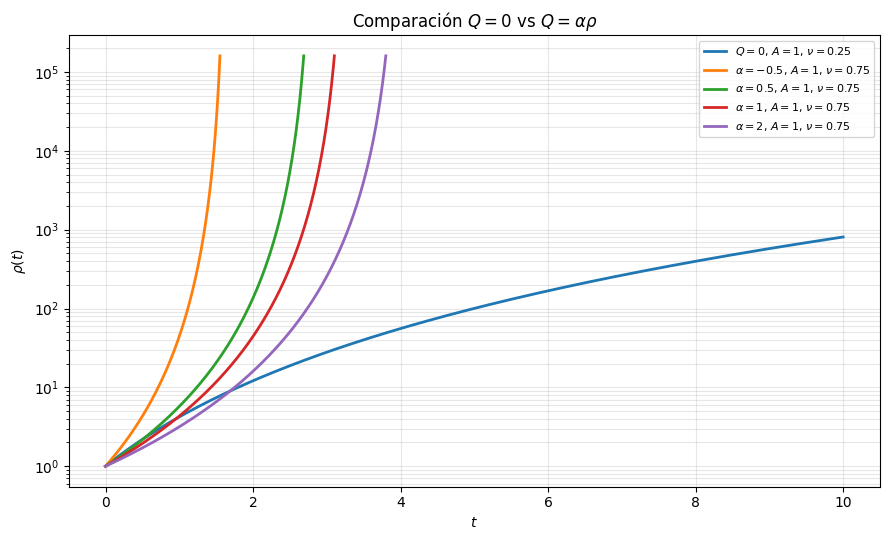

In [23]:
plot_quantity_for_rows(
    rows_compare,
    quantity="rho",
    ylabel=r"$\rho(t)$",
    title=r"Comparación $Q=0$ vs $Q=\alpha\rho$",
)

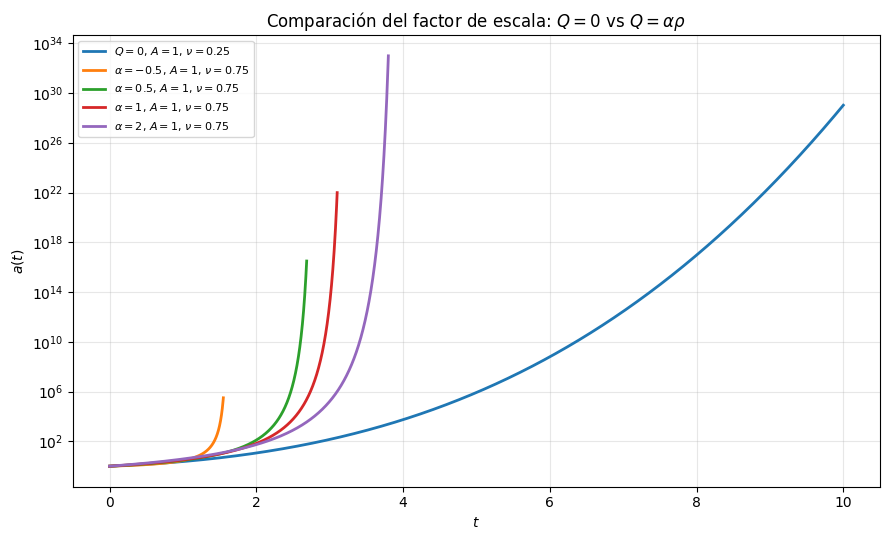

In [24]:
plot_quantity_for_rows(
    rows_compare,
    quantity="a",
    ylabel=r"$a(t)$",
    title=r"Comparación del factor de escala: $Q=0$ vs $Q=\alpha\rho$",
)

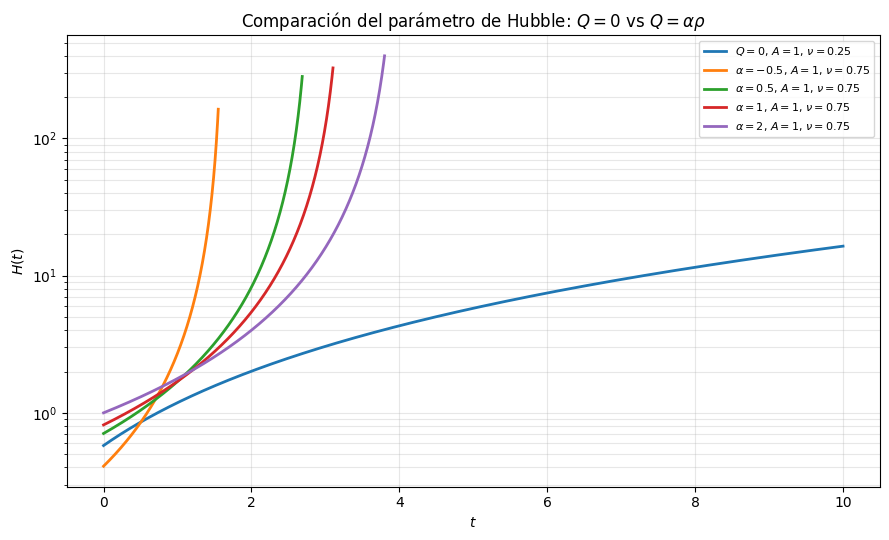

In [25]:
plot_quantity_for_rows(
    rows_compare,
    quantity="H",
    ylabel=r"$H(t)$",
    title=r"Comparación del parámetro de Hubble: $Q=0$ vs $Q=\alpha\rho$",
)

## XP

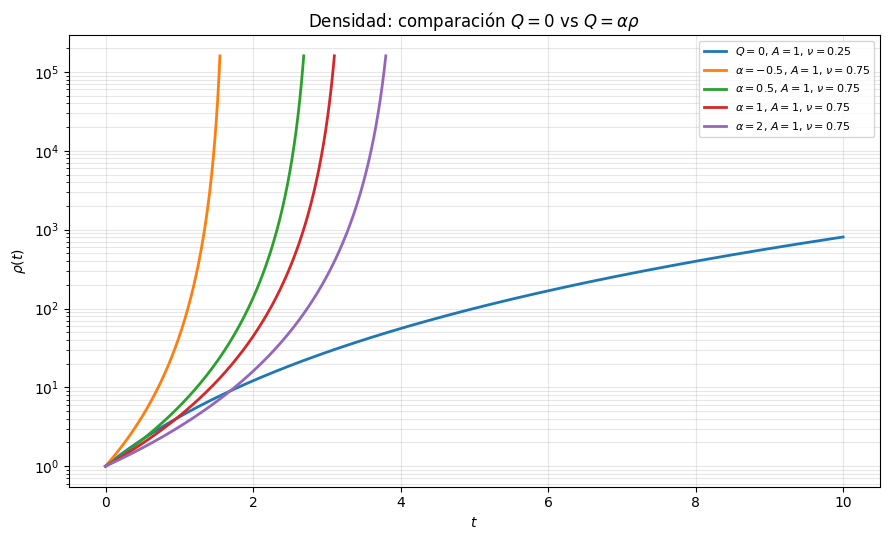

In [26]:
plot_quantity_for_rows(
    rows_compare,
    quantity="rho",
    ylabel=r"$\rho(t)$",
    title=r"Densidad: comparación $Q=0$ vs $Q=\alpha\rho$",
)

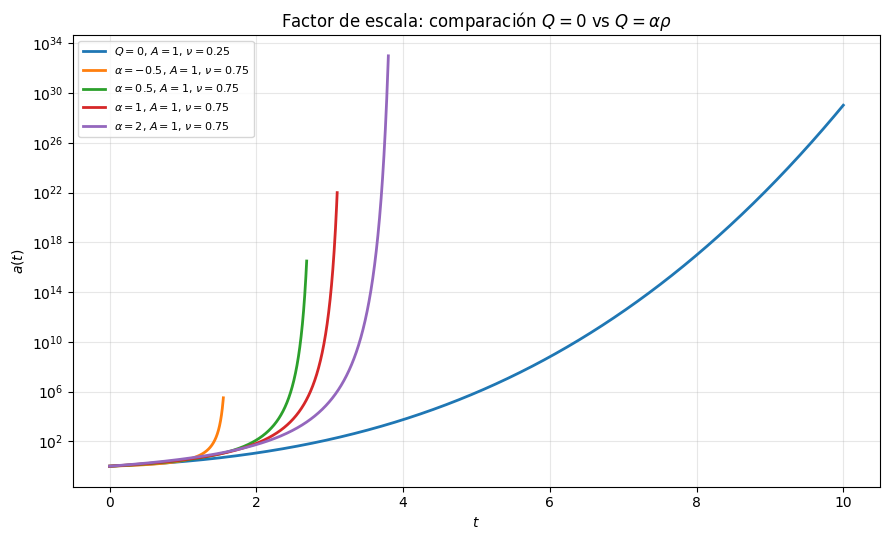

In [27]:
plot_quantity_for_rows(
    rows_compare,
    quantity="a",
    ylabel=r"$a(t)$",
    title=r"Factor de escala: comparación $Q=0$ vs $Q=\alpha\rho$",
)

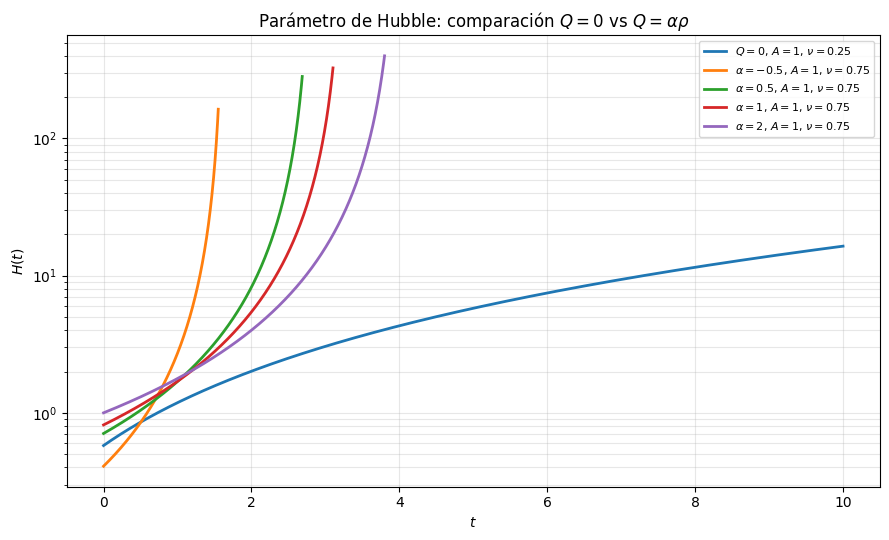

In [28]:
plot_quantity_for_rows(
    rows_compare,
    quantity="H",
    ylabel=r"$H(t)$",
    title=r"Parámetro de Hubble: comparación $Q=0$ vs $Q=\alpha\rho$",
)

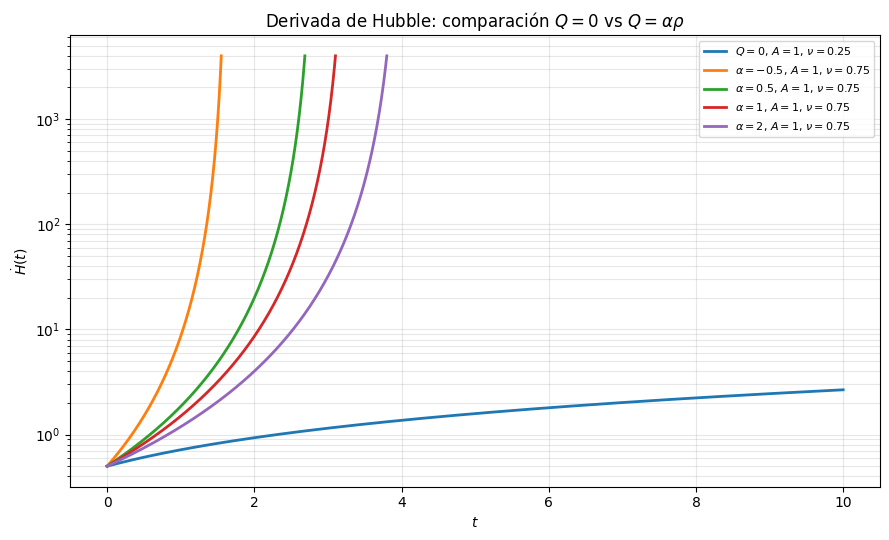

In [29]:
plot_quantity_for_rows(
    rows_compare,
    quantity="Hdot",
    ylabel=r"$\dot H(t)$",
    title=r"Derivada de Hubble: comparación $Q=0$ vs $Q=\alpha\rho$",
)

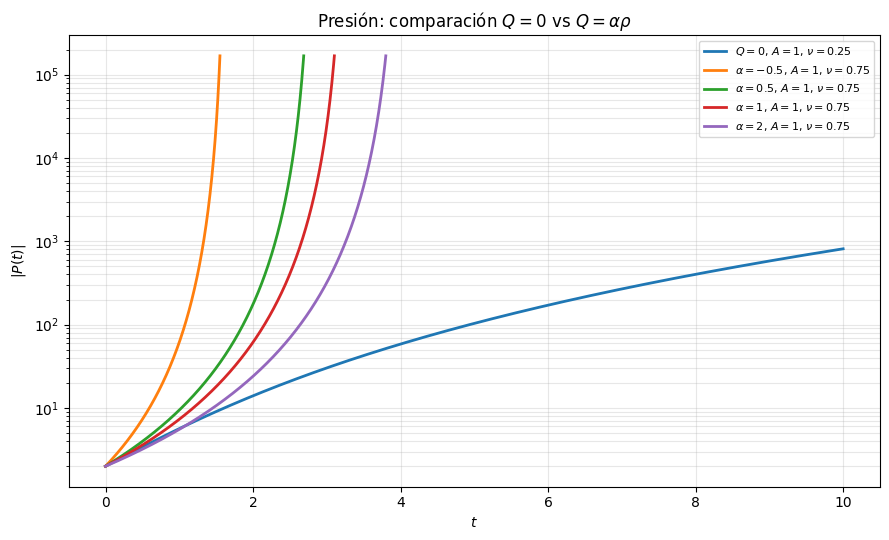

In [30]:
plot_quantity_for_rows(
    rows_compare,
    quantity="P_abs",
    ylabel=r"$|P(t)|$",
    title=r"Presión: comparación $Q=0$ vs $Q=\alpha\rho$",
)

In [31]:
row_example = select_closest_case(
    df_alpha,
    A=1.0,
    nu=0.75,
    alpha=0.5,
    rho0=1.0,
)

row_example[
    ["model_name", "A", "nu", "alpha", "rho0", "singularity_type", "singular_time"]
]

,model_name,A,nu,alpha,rho0,singularity_type,singular_time
298,phantom_qalpha_rho,1.0,0.75,0.5,1.0,Type I / Big Rip,2.828427


In [32]:
model_example = build_model_from_dataset_row(row_example.iloc[0])

t_values = make_time_grid_from_dataset_row(
    row_example.iloc[0],
    n_points=1500,
    fraction=0.97,
    t_end_default=10.0,
)

df_example = model_example.evaluate_background_t(t_values)

df_example.head()

,t,a,rho,Q,P,rho_eff,H,Hdot,w
0,0.000000,1.000000,1.000000,0.500000,-2.000000,1.500000,0.707107,0.500000,-2.000000
1,0.001830,1.001296,1.002593,0.501296,-2.004536,1.503889,0.708023,0.500972,-1.999353
2,0.003661,1.002595,1.005194,0.502597,-2.009086,1.507790,0.708941,0.501946,-1.998706
3,0.005491,1.003898,1.007803,0.503902,-2.013650,1.511705,0.709860,0.502923,-1.998059
4,0.007321,1.005204,1.010421,0.505210,-2.018226,1.515631,0.710782,0.503903,-1.997412


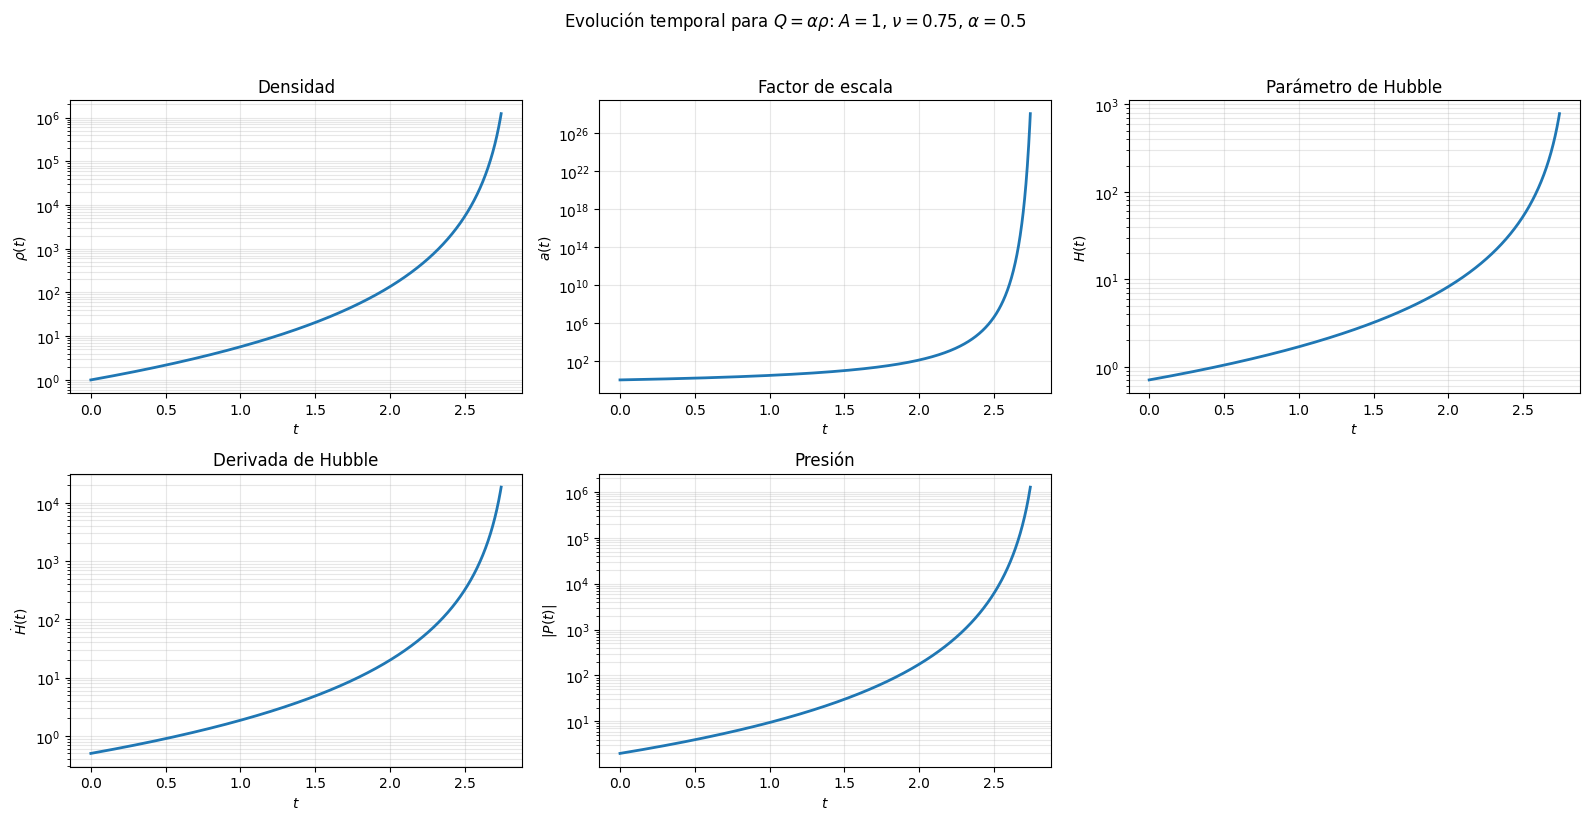

In [33]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

axes[0].plot(df_example["t"], df_example["rho"], linewidth=2)
axes[0].set_ylabel(r"$\rho(t)$")
axes[0].set_title(r"Densidad")

axes[1].plot(df_example["t"], df_example["a"], linewidth=2)
axes[1].set_ylabel(r"$a(t)$")
axes[1].set_title(r"Factor de escala")

axes[2].plot(df_example["t"], df_example["H"], linewidth=2)
axes[2].set_ylabel(r"$H(t)$")
axes[2].set_title(r"Parámetro de Hubble")

axes[3].plot(df_example["t"], df_example["Hdot"], linewidth=2)
axes[3].set_ylabel(r"$\dot H(t)$")
axes[3].set_title(r"Derivada de Hubble")

axes[4].plot(df_example["t"], np.abs(df_example["P"]), linewidth=2)
axes[4].set_ylabel(r"$|P(t)|$")
axes[4].set_title(r"Presión")

axes[5].axis("off")

for ax in axes[:5]:
    ax.set_xlabel(r"$t$")
    ax.set_yscale("log")
    ax.grid(True, which="both", alpha=0.3)

fig.suptitle(
    rf"Evolución temporal para $Q=\alpha\rho$: "
    rf"$A={row_example.iloc[0]['A']:.2g}$, "
    rf"$\nu={row_example.iloc[0]['nu']:.2g}$, "
    rf"$\alpha={row_example.iloc[0]['alpha']:.2g}$",
    y=1.02,
)

plt.tight_layout()
plt.show()